<a href="https://colab.research.google.com/github/anujjakhotiya/AI-DL_2026/blob/main/AI_DL_Project_2403A51016.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Fresh Produce Quality Detection Using CNN:

1. Install Libraries

In [ ]:
!pip -q install kagglehub gradio scikit-learn seaborn

2. Download Dataset

In [ ]:
# Download Fruit and Vegetable Healthy vs Rotten Dataset
import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "muhammad0subhan/fruit-and-vegetable-disease-healthy-vs-rotten"
)

print("Dataset Path:", dataset_path)

Using Colab cache for faster access to the 'fruit-and-vegetable-disease-healthy-vs-rotten' dataset.
Dataset Path: /kaggle/input/fruit-and-vegetable-disease-healthy-vs-rotten


3. Import Libraries and Prepare Dataset

In [ ]:
# Import Libraries and Detect Dataset Classes
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
data_dir = None

for root, dirs, files_list in os.walk(dataset_path):
    valid_dirs = []
    for d in dirs:
        folder = os.path.join(root, d)
        try:
            if any(f.lower().endswith(extensions) for f in os.listdir(folder)):
                valid_dirs.append(d)
        except PermissionError:
            pass
    if len(valid_dirs) >= 20:
        data_dir = root
        break

if data_dir is None:
    raise FileNotFoundError("Could not find the dataset class folders.")

classes = sorted([
    d for d in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, d))
    and any(f.lower().endswith(extensions)
            for f in os.listdir(os.path.join(data_dir, d)))
])

samples = []
for label, name in enumerate(classes):
    folder = os.path.join(data_dir, name)
    for file in os.listdir(folder):
        if file.lower().endswith(extensions):
            samples.append((os.path.join(folder, file), label))

labels = np.array([y for _, y in samples])
indices = np.arange(len(samples))

train_idx, temp_idx = train_test_split(
    indices, test_size=0.20, random_state=SEED, stratify=labels
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED,
    stratify=labels[temp_idx]
)

print("Classes:", len(classes), classes)
print("Total images:", len(samples))
print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

Device: cpu
Classes: 28 ['Apple__Healthy', 'Apple__Rotten', 'Banana__Healthy', 'Banana__Rotten', 'Bellpepper__Healthy', 'Bellpepper__Rotten', 'Carrot__Healthy', 'Carrot__Rotten', 'Cucumber__Healthy', 'Cucumber__Rotten', 'Grape__Healthy', 'Grape__Rotten', 'Guava__Healthy', 'Guava__Rotten', 'Jujube__Healthy', 'Jujube__Rotten', 'Mango__Healthy', 'Mango__Rotten', 'Orange__Healthy', 'Orange__Rotten', 'Pomegranate__Healthy', 'Pomegranate__Rotten', 'Potato__Healthy', 'Potato__Rotten', 'Strawberry__Healthy', 'Strawberry__Rotten', 'Tomato__Healthy', 'Tomato__Rotten']
Total images: 29291
Training: 23432
Validation: 2929
Testing: 2930


4. Image Preprocessing and Data Augmentation

In [ ]:
# Resize, Normalize and Augment Images
IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

class ProduceDataset(Dataset):
    def __init__(self, samples, indices, transform):
        self.samples = samples
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        path, label = self.samples[self.indices[i]]
        image = Image.open(path).convert("RGB")
        return self.transform(image), label

train_ds = ProduceDataset(samples, train_idx, train_transform)
val_ds = ProduceDataset(samples, val_idx, eval_transform)
test_ds = ProduceDataset(samples, test_idx, eval_transform)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True
)

print("Data loaders created successfully.")

Data loaders created successfully.


5. Visualize Sample Images

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


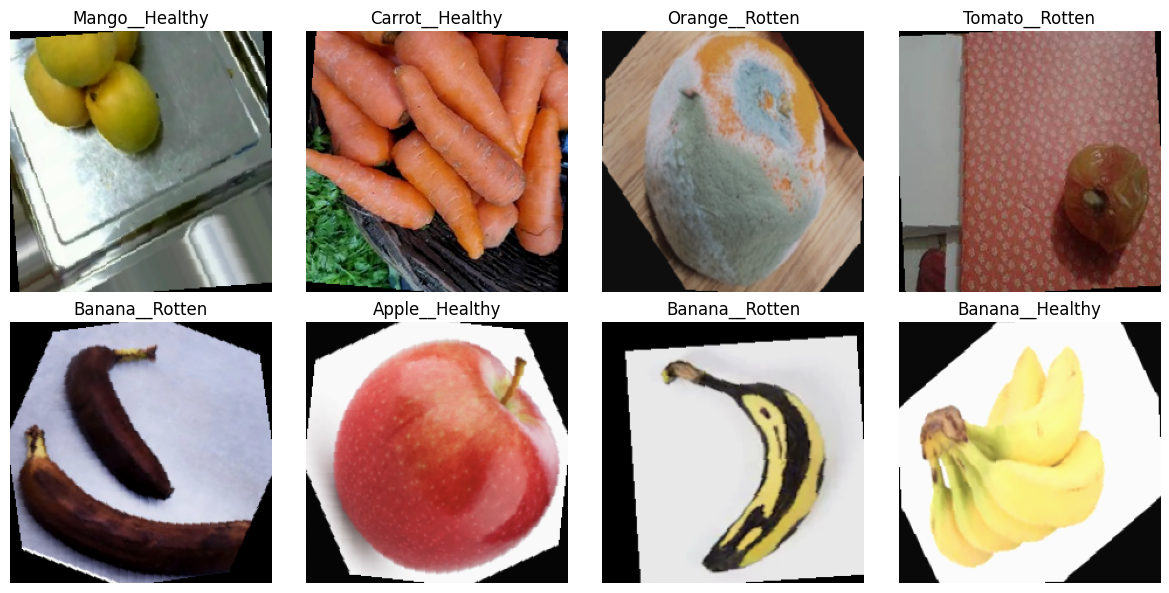

In [ ]:
# Display Sample Fruit and Vegetable Images
images, targets = next(iter(train_loader))

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    img = (images[i] * std + mean).clamp(0, 1)
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(classes[targets[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

6. Build CNN Using Transfer Learning

In [ ]:
# Build ResNet18 Model for Quality Classification
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(), lr=0.0001, weight_decay=1e-4
)

print("Model ready!")

Model ready!


7. Train the Model

In [ ]:
# Fast Training for Fresh Produce Quality Detection
from torch.utils.data import Subset, DataLoader
import numpy as np

FAST_TRAIN_SIZE = min(4000, len(train_ds))
FAST_VAL_SIZE = min(1000, len(val_ds))

train_fast = Subset(train_ds, np.random.choice(
    len(train_ds), FAST_TRAIN_SIZE, replace=False
))
val_fast = Subset(val_ds, np.random.choice(
    len(val_ds), FAST_VAL_SIZE, replace=False
))

train_loader = DataLoader(
    train_fast, batch_size=64, shuffle=True, num_workers=2
)
val_loader = DataLoader(
    val_fast, batch_size=64, shuffle=False, num_workers=2
)

EPOCHS = 3
best_val_acc = 0
history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": []
}

for epoch in range(EPOCHS):
    model.train()
    loss_sum = correct = total = 0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
        total += len(y)

    train_loss = loss_sum / total
    train_acc = 100 * correct / total

    model.eval()
    loss_sum = correct = total = 0

    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += criterion(out, y).item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)

    val_loss = loss_sum / total
    val_acc = 100 * correct / total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_fresh_produce_model.pth")

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

print("Training completed!")

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 1/3 | Train Loss: 1.2478 | Train Acc: 69.03% | Val Loss: 0.4717 | Val Acc: 86.60%


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 2/3 | Train Loss: 0.3181 | Train Acc: 92.78% | Val Loss: 0.2392 | Val Acc: 93.80%


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 3/3 | Train Loss: 0.1336 | Train Acc: 97.67% | Val Loss: 0.1809 | Val Acc: 95.00%
Training completed!


8. Plot Accuracy and Loss

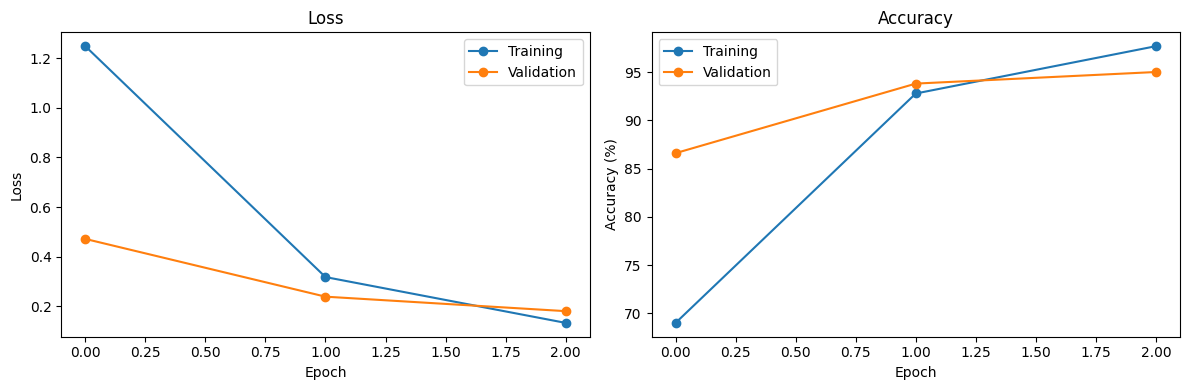

In [11]:
# Visualize Training and Validation Performance
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], marker="o", label="Training")
plt.plot(history["val_loss"], marker="o", label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], marker="o", label="Training")
plt.plot(history["val_acc"], marker="o", label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout()
plt.show()

9. Evaluate the Model

In [12]:
# Test Accuracy, Precision, Recall and F1-Score
model.load_state_dict(torch.load(
    "best_fresh_produce_model.pth", map_location=device
))
model.eval()

all_preds, all_labels = [], []

with torch.no_grad():
    for x, y in test_loader:
        outputs = model(x.to(device))
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(y.numpy())

print(f"Test Accuracy: {accuracy_score(all_labels, all_preds)*100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    all_labels, all_preds,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Test Accuracy: 94.81%

Classification Report:
                      precision    recall  f1-score   support

      Apple__Healthy       0.99      0.95      0.97       244
       Apple__Rotten       0.96      0.96      0.96       293
     Banana__Healthy       1.00      0.97      0.99       200
      Banana__Rotten       0.97      1.00      0.99       280
 Bellpepper__Healthy       0.90      0.93      0.92        61
  Bellpepper__Rotten       0.70      0.75      0.72        59
     Carrot__Healthy       0.94      0.97      0.95        62
      Carrot__Rotten       0.94      0.88      0.91        58
   Cucumber__Healthy       0.92      0.98      0.95        61
    Cucumber__Rotten       0.92      0.80      0.85        59
      Grape__Healthy       0.77      1.00      0.87        20
       Grape__Rotten       1.00      0.65      0.79        20
      Guava__Healthy       1.00      1.00      1.00        20
       Guava__Rotten       0.90      0.95      0.93        20
     Jujube__Healthy   

Confusion Matrix

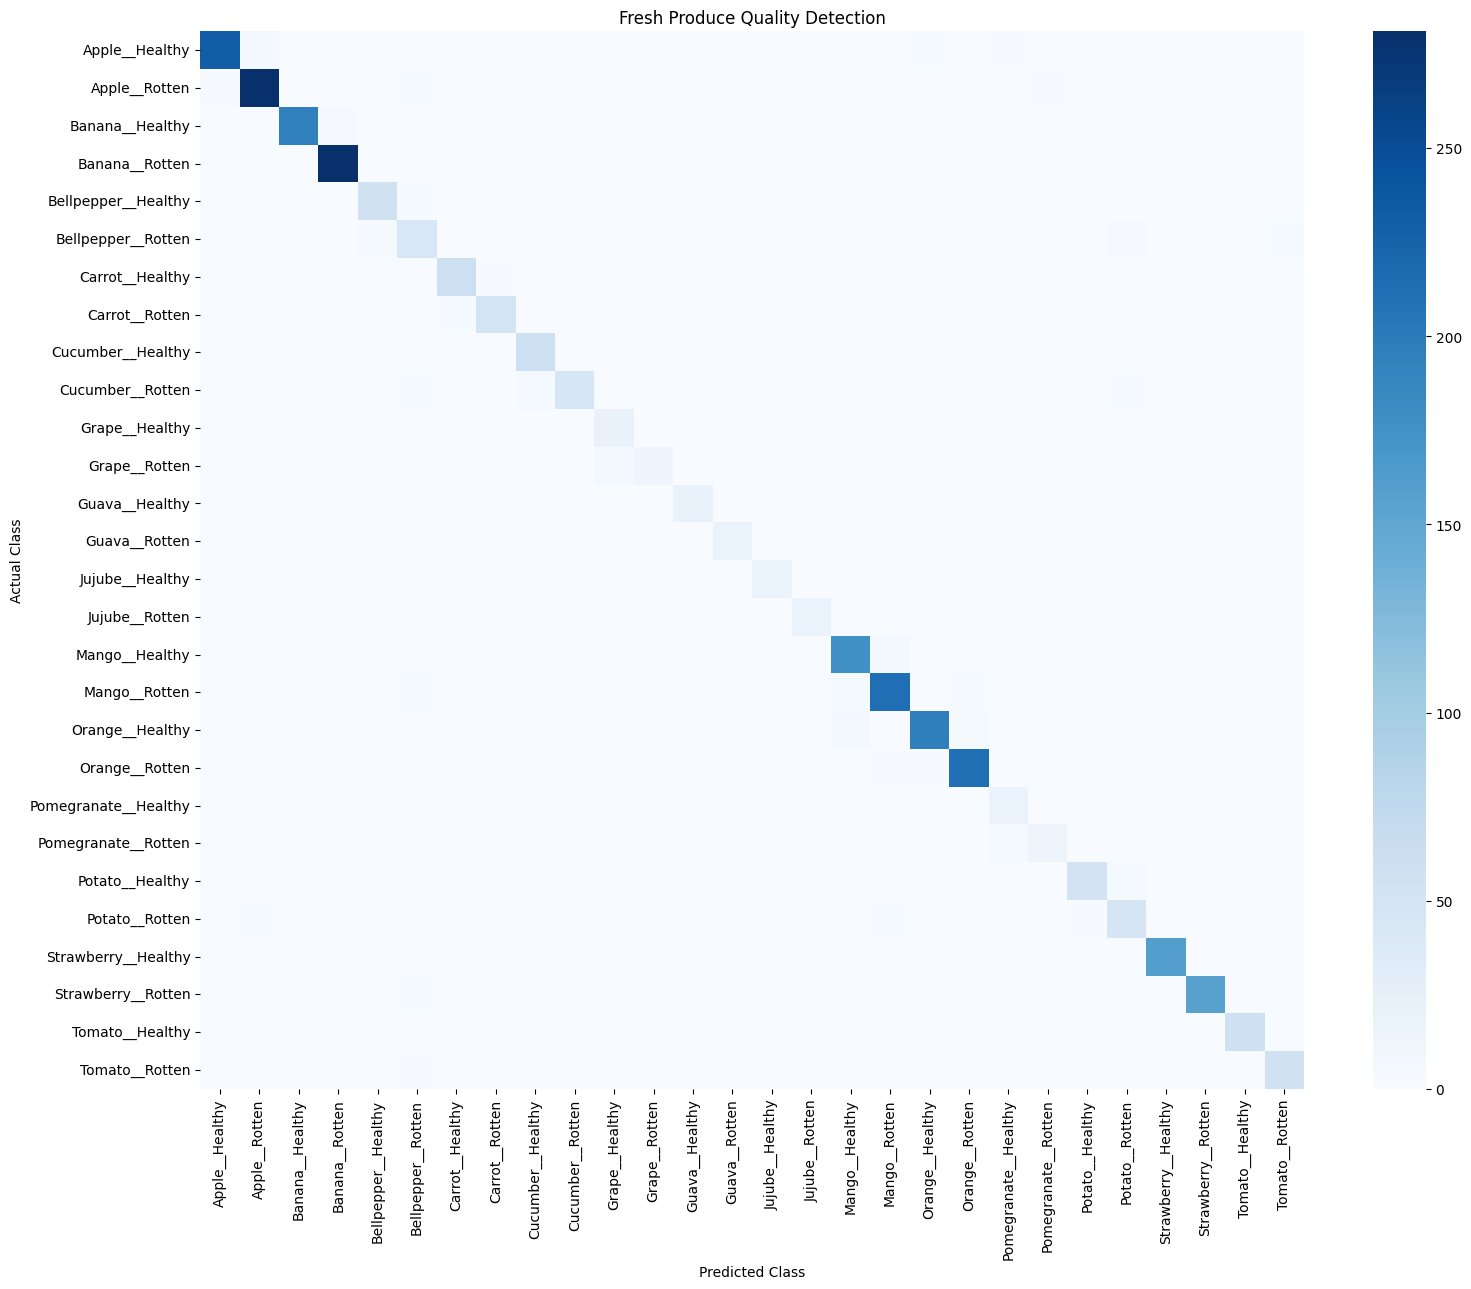

In [13]:
# Plot the Confusion Matrix
cm = confusion_matrix(
    all_labels, all_preds, labels=list(range(len(classes)))
)

plt.figure(figsize=(16, 13))
sns.heatmap(cm, cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("Fresh Produce Quality Detection")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

11. Predict Freshness from an Uploaded Image

Saving download.webp to download.webp


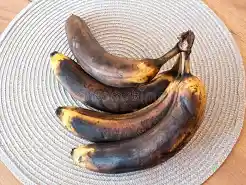

Predicted Class: Banana  Rotten
Confidence: 92.73%
Quality: Rotten


In [14]:
# Upload an Image and Predict Its Quality
from google.colab import files
from IPython.display import display

def predict_image(image):
    image = image.convert("RGB")
    x = eval_transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        probabilities = torch.softmax(model(x), dim=1)[0]
        confidence, idx = probabilities.max(0)

    label = classes[idx.item()]
    print("Predicted Class:", label.replace("_", " "))
    print(f"Confidence: {confidence.item()*100:.2f}%")

    if "rotten" in label.lower():
        print("Quality: Rotten")
    elif "healthy" in label.lower() or "fresh" in label.lower():
        print("Quality: Fresh / Healthy")
    else:
        print("Quality: Refer to predicted class.")

uploaded = files.upload()

for filename in uploaded:
    image = Image.open(filename)
    display(image)
    predict_image(image)

12. Save and Download the Model

In [15]:
# Save the Trained Model and Class Names
torch.save({
    "model_state_dict": model.state_dict(),
    "classes": classes,
    "img_size": IMG_SIZE
}, "Fresh_Produce_Quality_Detection.pth")

files.download("Fresh_Produce_Quality_Detection.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>